In [23]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

rng = np.random.default_rng(100)

def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

## Sequential Experimentation

- In the real world, we have to make decisions in real time
- Data arrive as we're taking action, and we have to update our behavior
- We're going to look at a simple $Z$-test, and investigate some options for search

## Revenue
- The **revenue** at a price $p$ is
$$
R(p) = \text{sales}(p) \times p
$$
- Sellers typically want to maximize revenue (or profit): Raising $p$ slightly increases the price paid for each unit sold, but reduces the number of units sold. A revenue-maximizing price must satisfy:
$$
R'(p^*) = \underbrace{\text{sales}(p^*) \times 1}_{\text{Increased revenue per sale}}+ \underbrace{\left.\dfrac{d \text{sales}(p)}{dp}\right|_{p=p^*}}_{\text{Lost marginal sales}} \times p^* = 0
$$
- This helps us think about trade-offs, but this is an idealized thought experiment: The world doesn't actually give us a `sales` function

## Revenue Management
- In the real world, we don't observe the $\text{sales}(p)$ function directly (you might model it, and we'll do that eventually, but a company like Uber often relies on experiments to adjust prices)
- Instead, you simply see how customers respond to changes in your pricing
- But changes in revenue are hard to attribute to a negative causal impact on sales, versus simply fewer customers engaging that day
- The lab is built around observing behavior, testing a hypothesis, and then updating prices
- This is called **stochastic optimization**: Each price you set is an experiment that yields information

## Key Function: `sales`
- The `sales(price=14.0, rng=None, mean_customers=30)` function is the core of the lab
- `mean_customers` scales the size of the market up and down: You'll want to be able to easily control the number of customers you experiment with later
- The rng argument is the numpy random number generator to use
- You set a `price`, and it returns a vector of customer choices (0=didn't buy, 1=buy) with a mean of your requested experiment size, `mean_customers`

## 1. Comparing Two Prices
- Our `sales(price, rng)` function generates a number of customers and their sales choices
- The number of customers who "browse" isn't affect by the price you choose, but whether they purchase is effected: Higher prices lead to lower sales
- Because sales are random/stochastic, it's difficult to know whether a change in price is truly profitable or not

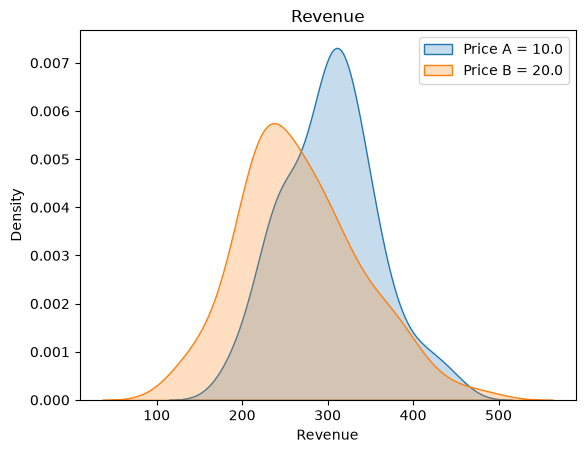

In [24]:
R = 100 # Test each price for 100 days
p_A = 10.0
p_B = 20.0
revenue_A = [ sales(p_A, rng=rng).sum() * p_A for t in range(R) ]
revenue_B = [ sales(p_B, rng=rng).sum() * p_B for t in range(R) ]
sns.kdeplot(revenue_A, fill=True, label=f"Price A = {p_A}").set(title=f"Revenue", xlabel="Revenue", ylabel="Density")
sns.kdeplot(revenue_B, fill=True, label=f"Price B = {p_B}")
plt.legend()

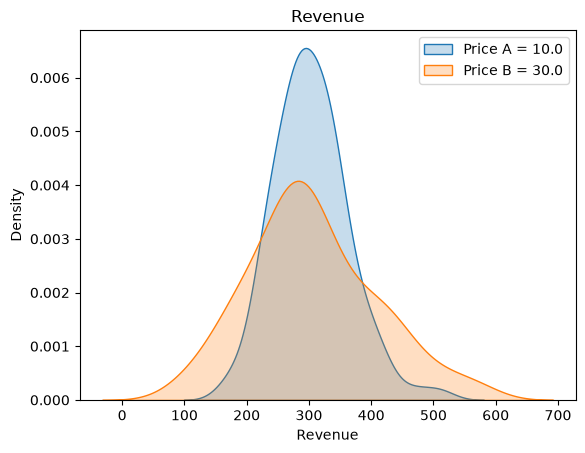

In [25]:
R = 100 # Test each price for 100 days
p_A = 10.0
p_B = 30.0
revenue_A = [ sales(p_A, rng=rng).sum() * p_A for t in range(R) ]
revenue_B = [ sales(p_B, rng=rng).sum() * p_B for t in range(R) ]
sns.kdeplot(revenue_A, fill=True, label=f"Price A = {p_A}").set(title=f"Revenue", xlabel="Revenue", ylabel="Density")
sns.kdeplot(revenue_B, fill=True, label=f"Price B = {p_B}")
plt.legend()

## Two-Sample $Z$-Test
- How can we compare revenue at two different price points?
- In the diabetes management lab, we used a fully non-parametric approach to comparing metformin versus rostiglatzione versus lifestyle
- Now that we know more about how Bootstrapping and classical inference interact, we can convert that two-way comparison into a statistical test
- The key fact to know is that if $X$ and $Y$ are independent and normally distributed with means $\mu_X$ and $\mu_Y$ and standard deviations $\sigma_X$ and $\sigma_Y$, then $X-Y$ is normally distributed with mean $\mu_X - \mu_Y$ and standard deviation $\sqrt{\sigma_X^2 + \sigma_Y^2}$

## Two-Sample $Z$-Test
- For large samples, the CLT lets us apply the difference-of-normals reasoning to approximately Normal sample means
- So let $\bar{X}_{n_X}$ be the mean of a sample of IID random variables of size $n_X$ with means $\mu_X$ and standard deviations $\sigma_X$ (and similarly for $\bar{Y}_{n_Y}$)
- The expectation of $\bar{X}_{n_X}$ is $\mu_X$, and the standard deviation of $\bar{X}_{n_X}$ is $\sigma_X/\sqrt{n_X}$ (and similarly for $\bar{Y}_{n_Y}$)
- Then the difference in $\Delta = \bar{X}_{n_X}-\bar{Y}_{n_Y}$ is approximately Normally distributed, with mean $\mu_X - \mu_Y$ and standard deviation $\sqrt{\sigma_X^2/n_X + \sigma_Y^2/n_Y}$
- What happens to the standard error of the mean as $n_X$ or $n_Y$ increase?
- If $\mu_X - \mu_Y$ is close to zero, is a difference in means easier or more difficult to detect?

## CIs for the Two-Sample $Z$-Test
- So the idea is: If $\bar{X}_{n_X}-\bar{Y}_{n_Y}$ has an approximately Normal sampling distribution with mean $\mu_X - \mu_Y$ and approximate the standard error with $\sqrt{\sigma_X^2/n_X + \sigma_Y^2/n_Y}$, we can compute, for instance, a 90% CI against a null of zero with
$$
\left( (\bar{X}_{n_X}-\bar{Y}_{n_Y}) - 1.645 \times \sqrt{\frac{s_X^2}{n_X} + \frac{s_Y^2}{n_Y}}, \quad (\bar{X}_{n_X}-\bar{Y}_{n_Y}) + 1.645 \times \sqrt{\frac{s_X^2}{n_X} + \frac{s_Y^2}{n_Y}} \right)
$$
- If 0 is in the interval, we can't distinguish whether the $X$ group has a higher or lower mean than the $Y$ group (fail to reject the null hypothesis). If 0 is not in the interval, it provides evidence against the null (reject the null hypothesis) and the $X$ and $Y$ groups are exhibiting statistically significant differences in outcomes 

<img src="./src/2szt.png" width="800px">

## Testing a Change in Price
- Let's compare prices of 10.00 and 15.00
- We'll draw a sample of customers at 10.00 and another at 15.00, and see what happens to revenue/customer

In [26]:
p_A = 10.00
p_B = 15.00
size = 100

sales_A = sales(p_A, mean_customers=size, rng=rng) * p_A # Compute revenue for each customer in A
sales_B = sales(p_B, mean_customers=size, rng=rng) * p_B # Compute revenue for each customer in B

print(f'There are {len(sales_A)} customers in A and {len(sales_B)} customers in B')

revenue_A = sales_A.mean() # Mean revenue per arriving customer in A
revenue_B = sales_B.mean() # Mean revenue per arriving customer in B

delta_R = revenue_B - revenue_A # Difference in mean revenue per arriving customer
std_error = np.sqrt(
    np.var(sales_A, ddof=1) / len(sales_A) +
    np.var(sales_B, ddof=1) / len(sales_B)
) # Standard Error

print(f'Change in mean revenue/customer is {delta_R:.3f} with standard error {std_error:.3f}')
confidence_interval = (delta_R - 1.96 * std_error, delta_R + 1.96 * std_error)
print(f"95% confidence interval for the difference in mean revenue/customer: ({confidence_interval[0]:.3f}, {confidence_interval[1]:.3f})")

There are 103 customers in A and 90 customers in B
Change in mean revenue/customer is -1.236 with standard error 0.791
95% confidence interval for the difference in mean revenue/customer: (-2.787, 0.315)


## Increasing the Sample Size
- But we're only getting handfuls of observations?
- There's a lot of noise here
- Set `experiment_size` to 100, 200, and 500 in turn; rerun the next experiment and power cells for each setting
- Each run computes 100 separate 90% confidence intervals

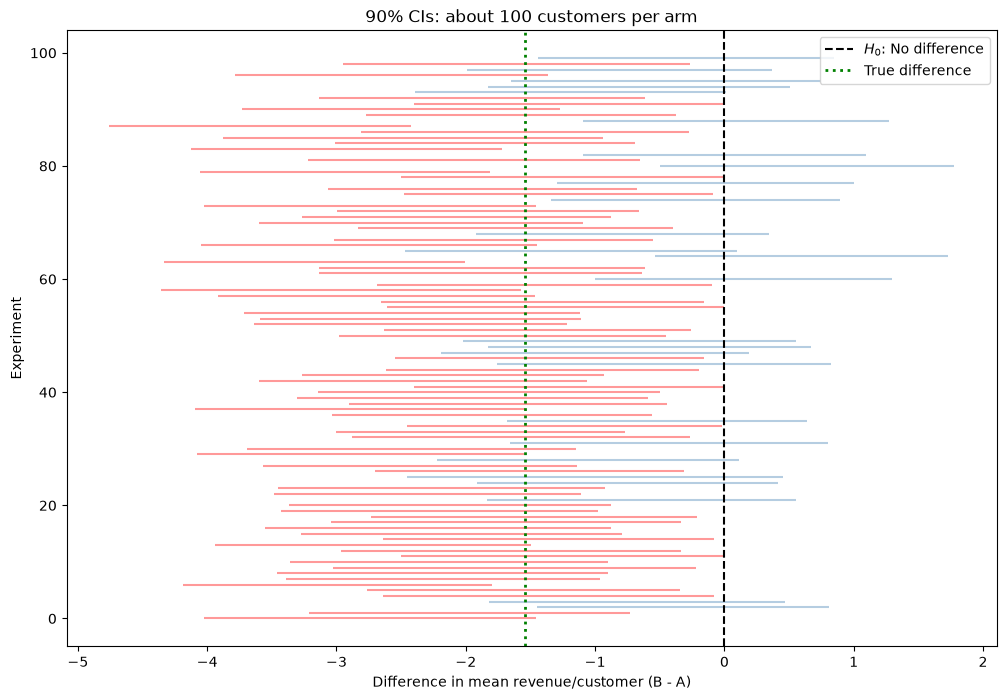

In [27]:
p_A = 10.00
p_B = 15.00
experiment_size = 100
CIs = []
for i in range(100):
    sales_A = sales(p_A, mean_customers = experiment_size, rng=rng) * p_A # Compute revenue for each customer in A
    sales_B = sales(p_B, mean_customers = experiment_size, rng=rng) * p_B # Compute revenue for each customer in B
    revenue_A = sales_A.mean() # Mean revenue per arriving customer in A
    revenue_B = sales_B.mean() # Mean revenue per arriving customer in B
    delta_R = revenue_B - revenue_A # Difference in mean revenue per arriving customer
    std_error = np.sqrt(
        np.var(sales_A, ddof=1) / len(sales_A) +
        np.var(sales_B, ddof=1) / len(sales_B)
    ) # Standard Error
    confidence_interval = (delta_R - 1.645 * std_error, delta_R + 1.645 * std_error)
    CIs.append(confidence_interval)

CIs = np.array(CIs)

fig, ax = plt.subplots(figsize=(12, 8))

for i, (lower, upper) in enumerate(CIs):
    ax.hlines(
        y=i,
        xmin=lower,
        xmax=upper,
        color='steelblue' if lower <= 0 <= upper else 'red',
        alpha=0.4,
        linewidth=1.5
    )

ax.axvline(0, color='black', linestyle='--', label='$H_0$: No difference')

# Model-based truth for checking coverage, not an estimate from these experiments.
true_delta = p_B * purchase_probability(p_B) - p_A * purchase_probability(p_A)
ax.axvline(
    true_delta,
    color='green',
    linestyle=':',
    linewidth=2,
    label='True difference'
)

ax.set_xlabel('Difference in mean revenue/customer (B - A)')
ax.set_ylabel('Experiment')
ax.set_title(f'90% CIs: about {experiment_size} customers per arm')
ax.legend()

plt.show()

## Statistical Power
- Our CIs cover the true param about 90% of the time, as they should, but whether or not we reject the null of 0 depends on the size of the experiment (the number of customers we experiment on)
- We define **(empirical) power** as
$$
\widehat{\text{Power}} = \dfrac{\text{Number of CIs excluding zero}}{\text{Number of Experiments}}
$$
and **(empirical) coverage** as
$$
\widehat{\text{Coverage}} = \dfrac{\text{Number of CIs including the true parameter value}}{\text{Number of Experiments}}
$$
- So you can see that as we increase the mean customers per experiment, the power increases significantly
- A nonsignificant result from an underpowered experiment does not establish that there is no effect
- Larger experiments require more customers and time, potentially spent at suboptimal prices
- Especially if the changes in price are small, the experiment will need to be powered to detect changes in revenue
- Potential gains from adjusting the price must be weighed against the cost of the experiment

In [28]:
power = np.mean(
    (CIs[:, 0] > 0) | (CIs[:, 1] < 0)
)
print(f"Empirical power: {power:.3%}")

coverage = np.mean(
    (CIs[:, 0] <= true_delta) & (CIs[:, 1] >= true_delta)
)
print(f"Empirical coverage/confidence (around 90%): {coverage:.3%}")


Empirical power: 74.000%
Empirical coverage/confidence (around 90%): 84.000%


## Power versus Confidence
- So the power varies with the size of the experiment: We're comparing to a null of zero
- Empirical coverage stays around 90%, with simulation noise and Normal-approximation error: We're cheating, and asking if the true value of the parameter is included in the interval
- This should help resolve a bit of the confusion around what confidence intervals are and how hypothesis testing works

## 2. Searching for the Optimal Price
- We have two broad strategies for searching for the optimal price:
    1. Grid Search: Pick a grid between 0 and 150, evaluate each price, and compare estimated revenue.
    2. Local Search: Use gradient ascent. Compare two nearby prices, $p_t-h$ and $p_t+h$, using fresh, independent customer samples:
    $$
    \hat g_t = \frac{\hat r(p_t+h)-\hat r(p_t-h)}{2h},
    \qquad p_{t+1}=p_t+\ell_t\hat g_t.
    $$
- Here $\hat r(p)$ is observed mean revenue per arriving customer, $h$ is the step size, and $\ell_t$ is the learning rate.
- Because expected traffic is independent of price, maximizing expected revenue per customer also maximizes expected total revenue for the same market size.
- A 90% interval containing zero can reflect low power; it does not certify an optimum, and you can get stuck in the neighborhood of an optimal price without ever arriving

## Local Search
- You do not **have** to use local search based on the gradient: You could do something entirely with sequential grid search
- Local search is potentially a powerful tool to refine your price in a neighborhood of the optimum, using inference and optimization together

In [29]:
def estimate_gradient(price, *, step=1.0, mean_customers=300, rng=None):
    if step <= 0:
        raise ValueError("step must be positive")
    rng = np.random.default_rng(rng)
    price = float(np.clip(price, 0, 75))
    price_low = max(0, price - step)
    price_high = min(75, price + step)
    low = price_low * sales(price_low, mean_customers=mean_customers, rng=rng)
    high = price_high * sales(price_high, mean_customers=mean_customers, rng=rng)
    if min(len(low), len(high)) < 2:
        raise ValueError("Need at least two customers per arm; increase mean_customers.")

    difference = high.mean() - low.mean()
    se = np.sqrt(low.var(ddof=1) / len(low) + high.var(ddof=1) / len(high))
    gap = price_high - price_low
    return {
        "price": price,
        "gradient": difference / gap,
        "gradient_se": se / gap,
        "ci_low": (difference - 1.645 * se) / gap,
        "ci_high": (difference + 1.645 * se) / gap,
        "customers": len(low) + len(high),
    }


# A positive slope suggests raising the price; a negative slope suggests lowering it.
local_experiment = estimate_gradient(price=30, rng=2026)
pd.DataFrame([local_experiment]).round(3)


,price,gradient,gradient_se,ci_low,ci_high,customers
0,30.0,-0.791,0.581,-1.747,0.165,607


In [30]:
def gradient_ascent(start_price, iterations=80, step=1.0,
                    learning_rate=2.0, mean_customers=300, seed=100):
    if iterations < 1:
        raise ValueError("iterations must be at least 1")
    search_rng = np.random.default_rng(seed)
    price = float(np.clip(start_price, 0, 75))
    records = []
    for iteration in range(iterations):
        estimate = estimate_gradient(price, step=step,
                                     mean_customers=mean_customers, rng=search_rng)
        rate = learning_rate / np.sqrt(iteration + 1)
        move = np.clip(rate * estimate["gradient"], -2.0, 2.0)
        next_price = float(np.clip(price + move, 0, 75))
        records.append({"iteration": iteration + 1, **estimate,
                        "learning_rate": rate, "next_price": next_price})
        price = next_price
    return pd.DataFrame(records)

path = gradient_ascent(start_price=32, seed=1000)
path[["iteration", "price", "gradient", "ci_low", "ci_high", "next_price"]].head(10)


,iteration,price,gradient,ci_low,ci_high,next_price
0,1,32.000000,-0.503708,-1.406801,0.399385,30.992584
1,2,30.992584,-1.677112,-2.587654,-0.766570,28.992584
2,3,28.992584,-0.396028,-1.313184,0.521127,28.535290
3,4,28.535290,0.035870,-0.890302,0.962042,28.571160
4,5,28.571160,-0.353588,-1.302404,0.595227,28.254901
5,6,28.254901,-0.885005,-1.824424,0.054413,27.532297
6,7,27.532297,0.202945,-0.743847,1.149738,27.685709
7,8,27.685709,0.043578,-0.866272,0.953427,27.716523
8,9,27.716523,0.324151,-0.603189,1.251490,27.932624
9,10,27.932624,0.075652,-0.825267,0.976571,27.980470


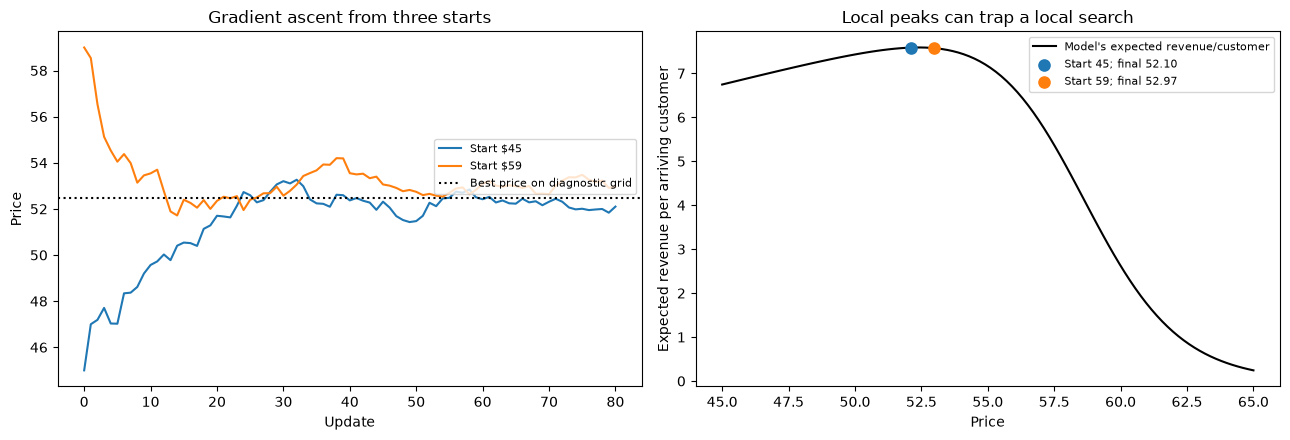

,start_price,final_price,search_customers,validation_customers,validation_revenue_per_customer,validation_se
0,45.0,52.100,47895,10036,7.548,0.183
1,59.0,52.973,47770,9894,7.678,0.187


In [31]:
# Only the diagnostic plot uses the model's true purchase curve.
# The search itself uses sales() at two nearby prices on every iteration.
starts = [45.0, 59.0]
ascent_paths = {
    start: gradient_ascent(start, seed=2026 + int(start))
    for start in starts
}
price_grid = np.linspace(45, 65, 100)
expected_revenue_per_customer = price_grid * purchase_probability(price_grid)
grid_best_price = price_grid[np.argmax(expected_revenue_per_customer)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[1].plot(price_grid, expected_revenue_per_customer,
             color="black", label="Model's expected revenue/customer")
evaluation_rng = np.random.default_rng(9001)
summary = []
for index, (start, history) in enumerate(ascent_paths.items()):
    color = f"C{index}"
    prices = np.r_[start, history["next_price"].to_numpy()]
    final_price = prices[-1]
    axes[0].plot(np.arange(len(prices)), prices,
                 color=color, label=f"Start ${start:g}")
    axes[1].scatter(final_price, final_price * purchase_probability(final_price),
                    color=color, s=65, zorder=3,
                    label=f"Start {start:g}; final {final_price:.2f}")

    # Evaluate the selected price with fresh customers, outside the search data.
    validation = final_price * sales(final_price, mean_customers=10_000,
                                      rng=evaluation_rng)
    summary.append({
        "start_price": start,
        "final_price": final_price,
        "search_customers": int(history["customers"].sum()),
        "validation_customers": len(validation),
        "validation_revenue_per_customer": validation.mean(),
        "validation_se": validation.std(ddof=1) / np.sqrt(len(validation)),
    })

axes[0].axhline(grid_best_price, color="black", linestyle=":",
                label="Best price on diagnostic grid")
axes[0].set(xlabel="Update", ylabel="Price", title="Gradient ascent from three starts")
axes[1].set(xlabel="Price", ylabel="Expected revenue per arriving customer",
            title="Local peaks can trap a local search")
axes[0].legend(loc="center right", bbox_to_anchor=(1, 0.62), fontsize=8)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

pd.DataFrame(summary).round(3)


## Lab
- You submit an .ipynb or .py that does two things:
    1. Determines an optimal price algorithmically (your code searches for and discovers an optimal price)
    2. Tracks the total number of consumers you have experimented with (at the optimum, each consumer has an expected profit of $11.925)

- The optimal price is between 0 and 70: There is no reason to consider prices outside that range
- There are multiple prices that appear optimal, but only one is globally optimal

- Provide a 1-3 page write-up explaining your design, including tables and plots as necessary:
    1. A one-paragraph summary of the problem
    2. Two paragraphs about how your design handles uncertainty about changes in revenue and selects prices
    3. Two paragraphs about challenges you faced and how you resolved them
    4. One paragraph that summarizes your results. In particular, how many consumers did you experiment on, what were your revenues during the experiments, and what percentage of the optimal profit ($11.925 per customer) did you capture?


## Issues to Consider

- How much data do you want to gather?
- Do you really want 90/95/99% confidence for setting prices?
- How do you combine brute force grid search?
- What is the minimum step size between prices you want to test?
- How should you adjust your sample size based on the information you are getting at a given price?
- If you cache experiments, can you gather data incrementally to constrain costs?

In [32]:
def estimate_gradient(price, *, step=1.0, mean_customers=300, rng=None):
    if step <= 0:
        raise ValueError("step must be positive")
    rng = np.random.default_rng(rng)
    price = float(np.clip(price, 0, 75))
    price_low = max(0, price - step)
    price_high = min(75, price + step)
    low = price_low * sales(price_low, mean_customers=mean_customers, rng=rng)
    high = price_high * sales(price_high, mean_customers=mean_customers, rng=rng)
    if min(len(low), len(high)) < 2:
        raise ValueError("Need at least two customers per arm; increase mean_customers.")

    difference = high.mean() - low.mean()
    se = np.sqrt(low.var(ddof=1) / len(low) + high.var(ddof=1) / len(high))
    gap = price_high - price_low
    return {
        "price": price,
        "gradient": difference / gap,
        "gradient_se": se / gap,
        "ci_low": (difference - 1.645 * se) / gap,
        "ci_high": (difference + 1.645 * se) / gap,
        "customers": len(low) + len(high),
        "revenue": low.sum() + high.sum(),     # EDITED: the only added line
    }


def gradient_ascent(start_price, iterations=80, step=1.0,
                    learning_rate=2.0, mean_customers=300, seed=100):
    if iterations < 1:
        raise ValueError("iterations must be at least 1")
    search_rng = np.random.default_rng(seed)
    price = float(np.clip(start_price, 0, 75))
    records = []
    for iteration in range(iterations):
        estimate = estimate_gradient(price, step=step,
                                     mean_customers=mean_customers, rng=search_rng)
        rate = learning_rate / np.sqrt(iteration + 1)
        move = np.clip(rate * estimate["gradient"], -2.0, 2.0)
        next_price = float(np.clip(price + move, 0, 75))
        records.append({"iteration": iteration + 1, **estimate,
                        "learning_rate": rate, "next_price": next_price})
        price = next_price
    return pd.DataFrame(records)

In [33]:
OPTIMAL_REVENUE_PER_CUSTOMER = 11.925  # given in the lab instructions

search_totals = {"customers": 0, "revenue": 0.0}  # running totals across every experiment we run
revenue_by_price = {}  # price -> array of per-customer revenue, accumulated over rounds

def run_experiment(price, mean_customers):
    price = round(price, 2)
    customer_revenue = price * sales(price, mean_customers=mean_customers, rng=rng)   # same line as cells 13/15
    search_totals["customers"] += len(customer_revenue)
    search_totals["revenue"] += customer_revenue.sum()
    if price in revenue_by_price:
        revenue_by_price[price] = np.concatenate([revenue_by_price[price], customer_revenue])
    else:
        revenue_by_price[price] = customer_revenue

In [34]:
def eliminate_prices(prices, mean_customers=30, z=2.6, max_rounds=6):
    """Successive elimination: test every candidate price, drop any price whose
    mean revenue is significantly below the current leader, double the sample, repeat."""
    candidates = [round(p, 2) for p in prices]
    for _ in range(max_rounds):
        for price in candidates:
            run_experiment(price, mean_customers)
        mean_revenue = {price: revenue_by_price[price].mean() for price in candidates}
        best_price = max(mean_revenue, key=mean_revenue.get)
        remaining = []
        for price in candidates:
            if price == best_price:
                remaining.append(price)
                continue
            delta_R = mean_revenue[best_price] - mean_revenue[price]          # cell 13
            std_error = np.sqrt(
                np.var(revenue_by_price[best_price], ddof=1) / len(revenue_by_price[best_price]) +
                np.var(revenue_by_price[price], ddof=1) / len(revenue_by_price[price])
            )                                                                   # cell 13
            if delta_R - z * std_error <= 0:    # CI includes 0: can't rule this price out
                remaining.append(price)
        candidates = remaining
        mean_customers *= 2
        if len(candidates) == 1:
            break
    return candidates, best_price

In [35]:
coarse_grid = np.arange(1, 70.5, 1.0)
survivors, best_price = eliminate_prices(coarse_grid)
print("Survivors:", survivors)
print("Best price:", best_price)
print("Customers so far:", search_totals["customers"])

Survivors: [np.float64(26.0), np.float64(27.0), np.float64(28.0), np.float64(29.0)]
Mean max: 28.0
Customers so far: 16617


In [36]:
fine_grid = np.arange(best_price - 2, best_price + 2.01, 0.25)
survivors, best_price = eliminate_prices(fine_grid, mean_customers=100, max_rounds=5)
print("Survivors:", survivors)
print("Best price:", best_price)
print("Customers so far:", search_totals["customers"])

Survivors: [np.float64(26.25), np.float64(26.5), np.float64(26.75), np.float64(27.0), np.float64(27.25), np.float64(27.5), np.float64(27.75), np.float64(28.0), np.float64(28.25), np.float64(28.5), np.float64(29.0), np.float64(29.5)]
Mean max: 28.0
Customers so far: 60647


In [37]:
ascent_path = gradient_ascent(start_price=best_price, iterations=20, mean_customers=100, seed=1234)
search_totals["customers"] += ascent_path["customers"].sum()
search_totals["revenue"] += ascent_path["revenue"].sum()
final_price = ascent_path["next_price"].iloc[-1]
print("Final price:", round(final_price, 2))
ascent_path[["iteration", "price", "gradient", "ci_low", "ci_high", "next_price"]].round(3)

Final price: 27.06


,iteration,price,gradient,ci_low,ci_high,next_price
0,1,28.000,0.435,-1.099,1.969,28.871
1,2,28.871,0.601,-1.033,2.236,29.721
2,3,29.721,-2.129,-3.787,-0.470,27.721
3,4,27.721,1.051,-0.571,2.673,28.773
4,5,28.773,-1.078,-2.706,0.551,27.809
5,6,27.809,-0.855,-2.440,0.730,27.111
6,7,27.111,-0.085,-1.636,1.465,27.046
7,8,27.046,-0.357,-1.921,1.206,26.794
8,9,26.794,0.719,-0.870,2.308,27.273
9,10,27.273,-0.430,-2.092,1.232,27.001


In [38]:
validation_revenue = final_price * sales(final_price, mean_customers=10_000,
                                         rng=np.random.default_rng(9001))     # REUSED from cell 23
validation_se = validation_revenue.std(ddof=1) / np.sqrt(len(validation_revenue))  # REUSED from cell 23
search_revenue_per_customer = search_totals["revenue"] / search_totals["customers"]

print(f"Final price: {final_price:.2f}")
print(f"Validation revenue/customer: {validation_revenue.mean():.3f} ± {validation_se:.3f}")
print(f"Search customers: {search_totals['customers']}")
print(f"Search revenue: {search_totals['revenue']:.2f}")
print(f"Search revenue/customer: {search_revenue_per_customer:.3f}")
print(f"% of optimal captured during search: "
      f"{search_revenue_per_customer / OPTIMAL_REVENUE_PER_CUSTOMER:.1%}")

Final price: 27.06
Validation revenue/customer: 11.867 ± 0.134
Search customers: 64644
Search revenue: 724950.67
Search revenue/customer: 11.215
% of optimal captured during search: 94.0%


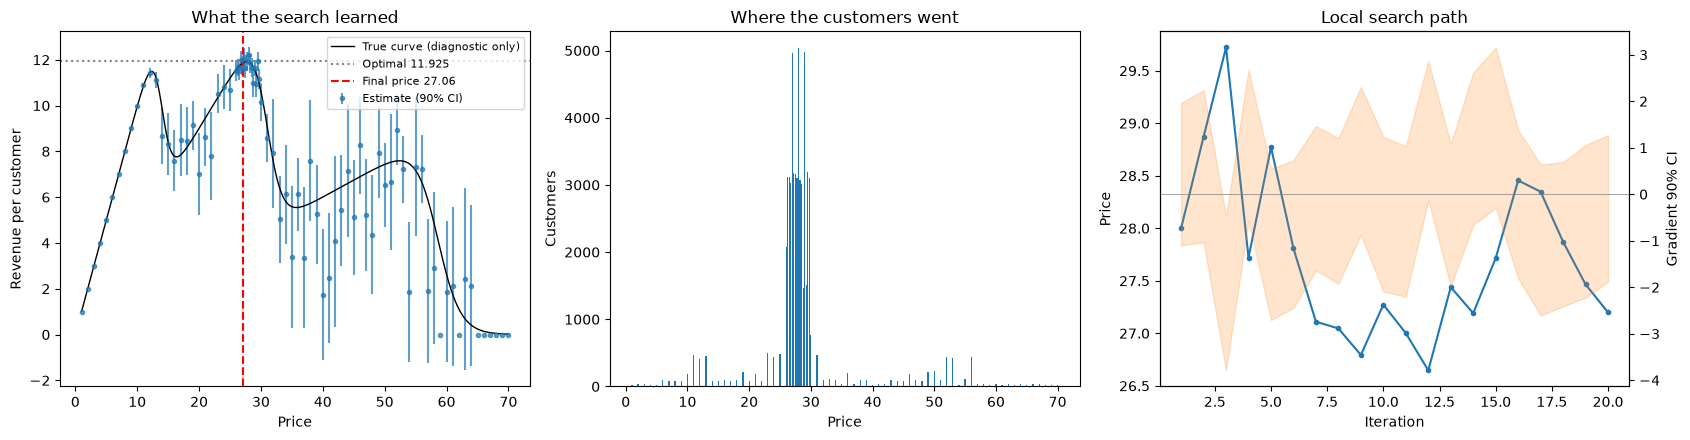

In [39]:
tested_prices = np.array(sorted(revenue_by_price))
mean_revenue = np.array([revenue_by_price[p].mean() for p in tested_prices])
std_errors = np.array([revenue_by_price[p].std(ddof=1) / np.sqrt(len(revenue_by_price[p])) for p in tested_prices])
customers_per_price = np.array([len(revenue_by_price[p]) for p in tested_prices])
price_curve = np.linspace(1, 70, 500)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Estimated revenue per customer
axes[0].errorbar(tested_prices, mean_revenue, yerr=1.645 * std_errors, fmt="o", ms=3, alpha=0.7,
                 label="Estimate (90% CI)")
axes[0].plot(price_curve, price_curve * purchase_probability(price_curve), color="black", lw=1,
             label="True curve (diagnostic only)")
axes[0].axhline(OPTIMAL_REVENUE_PER_CUSTOMER, color="gray", ls=":",
                label=f"Optimal {OPTIMAL_REVENUE_PER_CUSTOMER}")
axes[0].axvline(final_price, color="red", ls="--", label=f"Final price {final_price:.2f}")
axes[0].set(xlabel="Price", ylabel="Revenue per customer", title="What the search learned")
axes[0].legend(fontsize=8)

# Customers spent at each price
axes[1].bar(tested_prices, customers_per_price, width=0.2)
axes[1].set(xlabel="Price", ylabel="Customers", title="Where the customers went")

# Gradient ascent path
axes[2].plot(ascent_path["iteration"], ascent_path["price"], marker="o", ms=3)
axes[2].set(xlabel="Iteration", ylabel="Price", title="Local search path")
gradient_axis = axes[2].twinx()
gradient_axis.fill_between(ascent_path["iteration"], ascent_path["ci_low"], ascent_path["ci_high"],
                           alpha=0.2, color="C1")
gradient_axis.axhline(0, color="gray", lw=0.5)
gradient_axis.set_ylabel("Gradient 90% CI")

fig.tight_layout()
plt.show()

- Provide a 1-3 page write-up explaining your design, including tables and plots as necessary:
    1. A one-paragraph summary of the problem
    2. Two paragraphs about how your design handles uncertainty about changes in revenue and selects prices
    3. Two paragraphs about challenges you faced and how you resolved them
    4. One paragraph that summarizes your results. In particular, how many consumers did you experiment on, what were your revenues during the experiments, and what percentage of the optimal profit ($11.925 per customer) did you capture?

In this scenarion, our problem is simple. We want to set a price for a product that will optimize revenue per customer. However, we do not know the demand curve for this product. This means that if we set the price too high, not enough people will want to buy it which will leave money on the table, but if we set the price too low then we will also leave profit on the table because customers may have been willing to pay more for it. Expected revenue at a price is the price times the probability that a customer buys, and that probability falls as the price rises. The only way to learn it is to run experiments: offer a price to a group of customers and record who buys. Each experiment is noisy, because both the number of customers and their purchase decisions are random, and each one costs us customers who may be seeing a bad price. The revenue curve also has several local peaks, so a search that only looks nearby can settle on the wrong one. The goal is to find the globally optimal price, which is worth an expected $11.925 per customer, while using as few customers as possible and keeping revenue high during the search.


This experiment constantly compares prices to each other to estimate their revenue per customer. An estimation like this is going to deal witha fair amount of uncertainty. Every price comparison is a statistical test, and we only drop a price when the data shows that it is clearly worse than the leading candidate. One element of uncertainty we have to account for is the variance in customers per day. There may be more customers on certain days due to factors that we are not interested in. To control for this, we are testing revenue per customer at each potential price as the average of (price * bought), so the total amount of customers doesn't matter, and this will include customers that came in but didn't purchase. Furthermore, for each price we compare with the leader, we include a two sample Z standard error wrapped around the difference in mean revenue between the two prices being compared. We only eliminate the price if the whole entire interval is above 0, and if not it is kept as a potential max. Our Z is 2.6 instead of 1.645, which would be standard for a 90% interval because we do not want to eliminate a potential global max, as this is much more costly than keeping some extra prices in for a while. We let the data accumulate every round so that no customer is lost, and the standard error begins to shrink as the sample continues to grow, helping us weed out prices as we go. 

Eventually, the experiement selects a price, and we do so in three steps. The first step is a coarse grid search. We start with every even dollar price from 1 to 70 with about 30 customers for each price to cover our whole range. This keeps us from stopping at a local peak. This left us between 26-29 with around 16,000 customers. The next step was a fine grid search. The leader was 28, so we looked at a $.25 step for anything within $2 of 28, and started at 100 cutomers per price. We were left with 12 candidate prices with $28 still in the lead. The final step was gradient ascent. We started at $28 and looked at prices +- $1 for 20 iterations and found $27.06 to be the optimal price. The grid search found the correct, global peak. The local search fine tuned the peak, and the gradient ascent allowed us to find the absolute max.

One of the challenges of this experiment was the falt top of the revenue curve. Revenue changes very little at the top, so the nearby prices are almost impossible to distiguish between statistically. It becomes harder and harder to weed out the wrong price as we get close to the maximum. It is very easy to test whether there is a meaningful difference between a price of $67, and a price of $27 because that's going to lead to a very different number of purchases. But $27 and $27.25 is much closer and will give a much more negligible difference. For example, the fine grid stage used a lot of customers to weed out only 5 of the prices we started with. Generally, if the prices are this close to each other, picking the wrong one won't be terribly costly, so in a real world business application, paying for the extra precision may not be worth it if it is expensive. We could've shortened this stage to make it less expensive but also less precise. 

Another challenge we ran into was making sure the data we collected at a price was actually being reused when we came back to that price. Each experiment's results are stored in a dictionary keyed by price, so that when we test a price again in a later round, the new customers get added to the ones we already have. The problem is that the fine grid is built with np.arange, and computers don't store decimals exactly, so a price that should be $28.00 can come out as $27.999999999. To Python, that's a completely different key than $28.00. That means the fine grid would start a brand new pool of data for $28 instead of building on the customers we'd already spent on it in the coarse grid. The standard error would be bigger than it should be, and we would be paying for customers we had already seen. To fix this, we round every price to the cent before running an experiment or saving the results. That way any two prices that are the same in dollars and cents share the same pool of data. Rounding to the cent also makes sense from a business standpoint, because you can't charge a customer a fraction of a penny anyway.

In total, we experimented on 64,644 customers. Most of them were spent in the first two stages: 16,617 in the coarse grid search, 44,030 in the fine grid search, and only 3,997 during gradient ascent. Over the whole search we brought in $724,950.67 in revenue, which works out to $11.215 per customer. That means we captured 94.0% of the optimal $11.925 per customer while we were still experimenting. That's a strong result considering that in the coarse grid we were sending customers to prices as far off as $1 and $70. The final price the experiment selected was $27.06. To check how good that price actually is, we tested it on a fresh group of 10,000 customers that weren't used in the search. It earned $11.867 per customer, give or take $0.134, which is about 99.5% of the optimal profit. The optimal value is well inside that margin, so statistically we can't tell our price apart from the true optimum. Looking back, the fine grid stage was the most expensive part by far, using more than two thirds of our customers. As we talked about earlier, that's because prices near the top of the revenue curve are so hard to tell apart.